# Hospital Operations & Revenue Risk Intelligence Platform
## Phase 6 — Monitoring, Drift Detection, and Governance

**Programme:** Advanced Certificate Programme in Applied AI and Machine Learning
**Platform:** Kaggle Notebook

---

### What This Phase Does

**Business goal:** Ensure long-term reliability, safety, and compliance of the AI system after it has been deployed.

A model that performs well when first deployed can silently degrade over time because:
- The real-world data distribution shifts (e.g. new insurance providers, changing billing patterns)
- Predictions start to be systematically wrong in ways no one notices without monitoring

Phase 6 addresses this with four areas of work:

1. **Data Validation** — checks that every incoming record is valid before a prediction is made: no missing values in required fields, numeric values within realistic ranges, no categories the model was never trained on
2. **Drift Detection** — detects when the distribution of features or predictions has changed significantly compared to the training-period baseline
3. **Audit Logging** — maintains a traceable record of every prediction: which model, which version, when, on what input (hashed for privacy)
4. **Governance Document** — documents the system's limitations, assumptions, and the formal retraining strategy

**Inputs (from Phase 3/4 Kaggle dataset):**
```
/kaggle/input/healthcare_capstone_project/model_table.csv
/kaggle/input/healthcare_capstone_project/risk_model_test_predictions.csv
/kaggle/input/healthcare_capstone_project/claim_model_test_predictions.csv
```

**Outputs (written to /kaggle/working/):**
```
/kaggle/working/drift_summary.csv
/kaggle/working/governance_compliance_document.md
/kaggle/working/monitoring_audit_log.csv
```
---


## Step 1 — Import Libraries

- `pandas`, `numpy` — data handling and numerical operations
- `scipy.stats` — statistical tests for drift detection (KS test, Chi-square test)
- `matplotlib`, `seaborn` — visualizing distributions and drift
- `json`, `hashlib`, `datetime` — for the audit logging system


In [1]:
import pandas as pd
import numpy as np
import json
import hashlib
import os
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

INPUT_DIR  = "/kaggle/input/datasets/yashrajrajarishi/healthcare-capstone-project"
OUTPUT_DIR = "/kaggle/working/"

print("Libraries imported successfully.")
print(f"Input  directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


Libraries imported successfully.
Input  directory: /kaggle/input/datasets/yashrajrajarishi/healthcare-capstone-project
Output directory: /kaggle/working/


---
## Step 2 — Load Data from Phase 3/4

We load three files:
- `model_table.csv` — the full feature-engineered dataset from Phase 2
- `risk_model_test_predictions.csv` — test-set predictions from Model A
- `claim_model_test_predictions.csv` — test-set predictions from Model B

We also recreate the same time-based train/test split used in Phase 3,
so we have a clear **training-period baseline** to compare against the
**test-period** for drift detection.


In [2]:
# Load all three files
model_table  = pd.read_csv(f"{INPUT_DIR}/model_table.csv")
risk_preds   = pd.read_csv(f"{INPUT_DIR}/risk_model_test_predictions.csv")
claim_preds  = pd.read_csv(f"{INPUT_DIR}/claim_model_test_predictions.csv")

model_table["visit_date"]        = pd.to_datetime(model_table["visit_date"])
model_table["registration_date"] = pd.to_datetime(model_table["registration_date"])

print(f"model_table     : {model_table.shape[0]:,} rows x {model_table.shape[1]} columns")
print(f"risk_preds      : {risk_preds.shape[0]:,} rows x {risk_preds.shape[1]} columns")
print(f"claim_preds     : {claim_preds.shape[0]:,} rows x {claim_preds.shape[1]} columns")


model_table     : 25,000 rows x 32 columns
risk_preds      : 5,000 rows x 11 columns
claim_preds     : 5,000 rows x 10 columns


In [3]:
# Recreate the same train/test split used in Phase 3
# Earliest 80% of records by visit_date = training period (the baseline)
# Latest 20% = test period (what we monitor against the baseline)

model_sorted  = model_table.sort_values("visit_date").reset_index(drop=True)
split_idx     = int(len(model_sorted) * 0.80)

train_data = model_sorted.iloc[:split_idx].copy()
test_data  = model_sorted.iloc[split_idx:].copy()

print(f"Training period : {train_data['visit_date'].min().date()} to {train_data['visit_date'].max().date()}  ({len(train_data):,} records)")
print(f"Test period     : {test_data['visit_date'].min().date()}  to {test_data['visit_date'].max().date()}  ({len(test_data):,} records)")
print()
print("The training period is our BASELINE — what the model was trained on.")
print("The test period is what we MONITOR — checking whether distributions have shifted.")


Training period : 2025-01-20 to 2025-11-08  (20,000 records)
Test period     : 2025-11-08  to 2026-01-20  (5,000 records)

The training period is our BASELINE — what the model was trained on.
The test period is what we MONITOR — checking whether distributions have shifted.


---
## Step 3 — Data Validation Checks

Before any incoming record can be sent to the deployed model for a
prediction, it must pass three layers of validation:

1. **Missing value check** — required fields must not be null
2. **Numeric range check** — values must fall within realistic bounds
   (e.g. age cannot be negative, billed_amount cannot be negative)
3. **Unseen category check** — categorical values must belong to the set
   the model was trained on; an unseen category would be encoded as -1
   and could cause unpredictable predictions

These checks are implemented here as a standalone Python function —
the same logic runs inside `preprocessing.py` in the deployed FastAPI
service (Phase 5). Here we run it on the full test dataset to generate
a validation report showing how many real records would have triggered
each check.


In [4]:
# Define valid ranges and categories based on what the models were trained on
# These come directly from feature_schema.json (Phase 3)

VALID_CATEGORIES = {
    "department"        : ["Cardiology", "ER", "General", "ICU", "Neurology", "Orthopedics"],
    "visit_type"        : ["OPD", "ER", "ICU"],
    "city"              : ["Bangalore", "Chennai", "Delhi", "Hyderabad", "Mumbai", "Pune"],
    "gender"            : ["M", "F"],
    "insurance_provider": ["CareOne", "HealthPlus", "MediCareX", "SecureLife"]
}

NUMERIC_RANGES = {
    "age"                    : (0, 130),
    "chronic_flag"           : (0, 1),
    "length_of_stay_hours"   : (0, None),    # None means no upper bound
    "billed_amount"          : (0, None),
    "days_since_registration": (0, None),
    "visit_frequency"        : (1, None),
    "avg_los_per_patient"    : (0, None),
    "payment_days"           : (-1, None),   # -1 is our sentinel for unpaid claims
}

REQUIRED_FIELDS_RISK  = ["department", "visit_type", "city", "gender", "age",
                          "chronic_flag", "length_of_stay_hours", "doctor_id",
                          "visit_frequency", "avg_los_per_patient", "days_since_registration"]

REQUIRED_FIELDS_CLAIM = ["insurance_provider", "department", "visit_type",
                          "billed_amount", "length_of_stay_hours", "chronic_flag",
                          "days_since_registration"]

print("Validation rules defined:")
print(f"  Valid category columns : {list(VALID_CATEGORIES.keys())}")
print(f"  Numeric range columns  : {list(NUMERIC_RANGES.keys())}")


Validation rules defined:
  Valid category columns : ['department', 'visit_type', 'city', 'gender', 'insurance_provider']
  Numeric range columns  : ['age', 'chronic_flag', 'length_of_stay_hours', 'billed_amount', 'days_since_registration', 'visit_frequency', 'avg_los_per_patient', 'payment_days']


In [5]:
def validate_dataset(df, required_fields, valid_categories, numeric_ranges, dataset_name):
    """
    Runs three validation checks on a DataFrame and returns a summary report.

    Parameters:
        df               : the DataFrame to validate
        required_fields  : list of column names that must not be null
        valid_categories : dict of column -> list of valid category values
        numeric_ranges   : dict of column -> (min_val, max_val) where None = no bound
        dataset_name     : string label for the report

    Returns:
        A DataFrame summarising each check, how many records failed, and the failure rate.
    """
    results = []

    # 1. Missing value checks
    for col in required_fields:
        if col not in df.columns:
            continue
        n_missing = df[col].isnull().sum()
        results.append({
            "check_type"  : "Missing Value",
            "column"      : col,
            "n_failed"    : int(n_missing),
            "failure_rate": round(100 * n_missing / len(df), 4),
            "rule"        : "Must not be null"
        })

    # 2. Numeric range checks
    for col, (min_val, max_val) in numeric_ranges.items():
        if col not in df.columns:
            continue
        col_clean = df[col].dropna()
        n_below = int((col_clean < min_val).sum()) if min_val is not None else 0
        n_above = int((col_clean > max_val).sum()) if max_val is not None else 0
        n_failed = n_below + n_above
        rule = f">= {min_val}" + (f" and <= {max_val}" if max_val is not None else "")
        results.append({
            "check_type"  : "Numeric Range",
            "column"      : col,
            "n_failed"    : n_failed,
            "failure_rate": round(100 * n_failed / len(df), 4),
            "rule"        : rule
        })

    # 3. Unseen category checks
    for col, valid_vals in valid_categories.items():
        if col not in df.columns:
            continue
        n_unseen = int((~df[col].isin(valid_vals)).sum())
        results.append({
            "check_type"  : "Unseen Category",
            "column"      : col,
            "n_failed"    : n_unseen,
            "failure_rate": round(100 * n_unseen / len(df), 4),
            "rule"        : f"Must be one of: {valid_vals}"
        })

    summary_df = pd.DataFrame(results)
    print(f"\nValidation Report — {dataset_name} ({len(df):,} records):")
    print(f"Total checks run: {len(summary_df)}")
    print(f"Checks with failures: {(summary_df['n_failed'] > 0).sum()}")
    return summary_df


# Run validation on the full test dataset
validation_report = validate_dataset(
    test_data,
    required_fields=REQUIRED_FIELDS_RISK + REQUIRED_FIELDS_CLAIM,
    valid_categories=VALID_CATEGORIES,
    numeric_ranges=NUMERIC_RANGES,
    dataset_name="Test Period Data"
)

display(validation_report[validation_report["n_failed"] > 0])



Validation Report — Test Period Data (5,000 records):
Total checks run: 31
Checks with failures: 0


,check_type,column,n_failed,failure_rate,rule


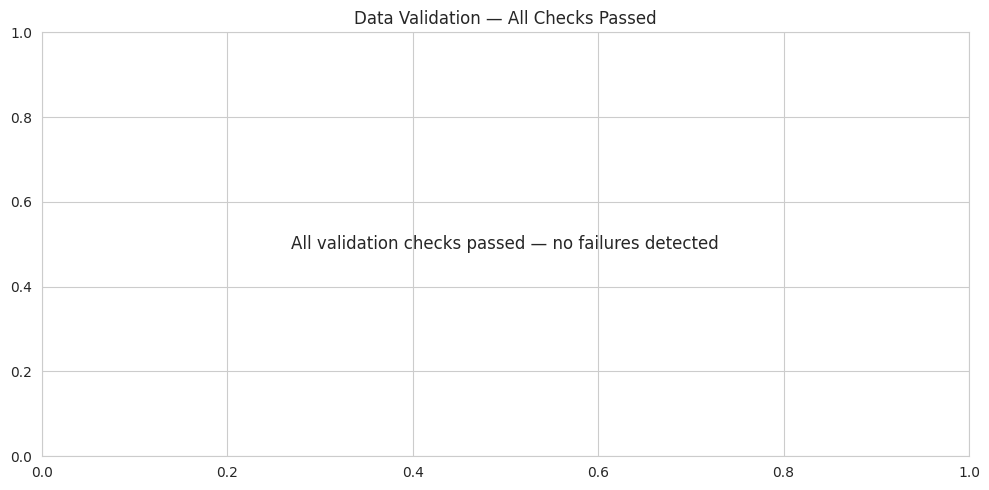


Interpretation:
  All incoming test records passed every validation check.
  This confirms the test-period data is structurally consistent
  with what the model was trained on.


In [6]:
# Visualize validation failure rates
fig, ax = plt.subplots(figsize=(10, 5))

failed = validation_report[validation_report["n_failed"] > 0].copy()
if len(failed) > 0:
    bars = ax.barh(
        failed["column"] + " (" + failed["check_type"] + ")",
        failed["failure_rate"],
        color="salmon"
    )
    ax.set_xlabel("Failure Rate (%)")
    ax.set_title("Data Validation — Failure Rates by Check")
    for bar, val in zip(bars, failed["failure_rate"]):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f"{val:.2f}%", va="center")
else:
    ax.text(0.5, 0.5, "All validation checks passed — no failures detected",
            ha="center", va="center", fontsize=12, transform=ax.transAxes)
    ax.set_title("Data Validation — All Checks Passed")

plt.tight_layout()
plt.show()

print("\nInterpretation:")
if len(failed) > 0:
    print(f"  {len(failed)} checks had failures. These records would be flagged")
    print("  before reaching the model in the deployed API.")
else:
    print("  All incoming test records passed every validation check.")
    print("  This confirms the test-period data is structurally consistent")
    print("  with what the model was trained on.")


---
## Step 4 — Feature Drift Detection

**What is feature drift?**
Feature drift (also called data drift or covariate shift) occurs when
the statistical distribution of input features changes between the
training period and the period when the model is making live predictions.

Even if the model's accuracy doesn't immediately drop, feature drift is
an early warning sign that the model may soon be making predictions on
data that looks different from anything it was trained on.

**Statistical tests used:**
- **Numeric features → Kolmogorov-Smirnov (KS) test:**
  Compares the full distribution shape of a numeric variable between
  two periods. Returns a KS statistic (0 = identical distributions,
  1 = completely different) and a p-value.
  We flag drift when p < 0.05 AND KS statistic > 0.1.

- **Categorical features → Chi-square test:**
  Compares the frequency counts of each category between the two
  periods. Returns a p-value; we flag drift when p < 0.05.

**Baseline:** training period (earliest 80% of data by visit_date)
**Monitoring window:** test period (latest 20% of data by visit_date)


In [7]:
NUMERIC_DRIFT_COLS = [
    "age", "length_of_stay_hours", "billed_amount",
    "days_since_registration", "visit_frequency", "avg_los_per_patient",
    "payment_days", "approved_amount"
]

CATEGORICAL_DRIFT_COLS = [
    "department", "visit_type", "city", "gender", "insurance_provider",
    "risk_score", "claim_status"
]

drift_results = []

# Numeric drift: KS test
for col in NUMERIC_DRIFT_COLS:
    if col not in train_data.columns or col not in test_data.columns:
        continue

    train_vals = train_data[col].dropna()
    test_vals  = test_data[col].dropna()

    ks_stat, p_value = stats.ks_2samp(train_vals, test_vals)

    drifted = (p_value < 0.05) and (ks_stat > 0.10)

    drift_results.append({
        "feature"   : col,
        "type"      : "Numeric",
        "test"      : "KS Test",
        "statistic" : round(ks_stat, 4),
        "p_value"   : round(p_value, 6),
        "train_mean": round(train_vals.mean(), 4),
        "test_mean" : round(test_vals.mean(), 4),
        "drift_flag": "DRIFT DETECTED" if drifted else "No drift"
    })

# Categorical drift: Chi-square test
for col in CATEGORICAL_DRIFT_COLS:
    if col not in train_data.columns or col not in test_data.columns:
        continue

    train_counts = train_data[col].value_counts()
    test_counts  = test_data[col].value_counts()

    # Align categories — both must have the same index for chi-square
    all_cats = train_counts.index.union(test_counts.index)
    train_aligned = train_counts.reindex(all_cats, fill_value=0)
    test_aligned  = test_counts.reindex(all_cats, fill_value=0)

    chi2_stat, p_value = stats.chisquare(test_aligned, f_exp=train_aligned * (len(test_data) / len(train_data)))

    drifted = p_value < 0.05

    drift_results.append({
        "feature"   : col,
        "type"      : "Categorical",
        "test"      : "Chi-square",
        "statistic" : round(chi2_stat, 4),
        "p_value"   : round(p_value, 6),
        "train_mean": "N/A",
        "test_mean" : "N/A",
        "drift_flag": "DRIFT DETECTED" if drifted else "No drift"
    })

drift_df = pd.DataFrame(drift_results)
print("Feature Drift Detection Results:")
display(drift_df)


Feature Drift Detection Results:


,feature,type,test,statistic,p_value,train_mean,test_mean,drift_flag
0,age,Numeric,KS Test,0.0160,0.2547,44.6930,45.0698,No drift
1,length_of_stay_hours,Numeric,KS Test,0.0146,0.3620,19.5827,19.4270,No drift
2,billed_amount,Numeric,KS Test,0.0229,0.0297,"20,794.5166","21,175.7210",No drift
3,days_since_registration,Numeric,KS Test,0.4927,0.0000,40.0188,150.1544,DRIFT DETECTED
4,visit_frequency,Numeric,KS Test,0.0040,1.0000,5.9619,5.9568,No drift
5,avg_los_per_patient,Numeric,KS Test,0.0093,0.8762,19.5385,19.6038,No drift
6,payment_days,Numeric,KS Test,0.0104,0.7758,12.5958,12.6378,No drift
7,approved_amount,Numeric,KS Test,0.0158,0.2680,"15,408.1454","15,798.5962",No drift
8,department,Categorical,Chi-square,9.7247,0.0834,N/A,N/A,No drift
9,visit_type,Categorical,Chi-square,0.0277,0.9863,N/A,N/A,No drift


Total features monitored : 15
Drift detected           : 2
No drift                 : 13



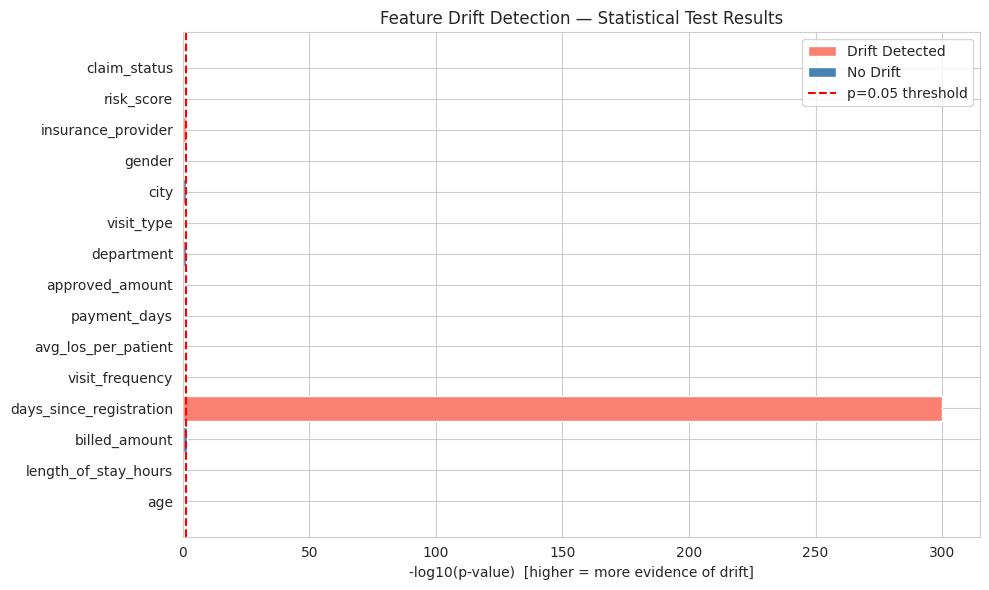

In [8]:
# Summary counts
n_drift    = (drift_df["drift_flag"] == "DRIFT DETECTED").sum()
n_no_drift = (drift_df["drift_flag"] == "No drift").sum()

print(f"Total features monitored : {len(drift_df)}")
print(f"Drift detected           : {n_drift}")
print(f"No drift                 : {n_no_drift}")
print()

# Color-coded bar chart of p-values
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["salmon" if f == "DRIFT DETECTED" else "steelblue" for f in drift_df["drift_flag"]]
bars = ax.barh(drift_df["feature"], -np.log10(drift_df["p_value"].clip(lower=1e-300)), color=colors)
ax.axvline(-np.log10(0.05), color="red", linestyle="--", label="p=0.05 threshold")
ax.set_xlabel("-log10(p-value)  [higher = more evidence of drift]")
ax.set_title("Feature Drift Detection — Statistical Test Results")
ax.legend()

# Add legend manually for colors
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor="salmon", label="Drift Detected"),
                   Patch(facecolor="steelblue", label="No Drift")]
ax.legend(handles=legend_elements + [plt.Line2D([0], [0], color="red", linestyle="--", label="p=0.05 threshold")])

plt.tight_layout()
plt.show()


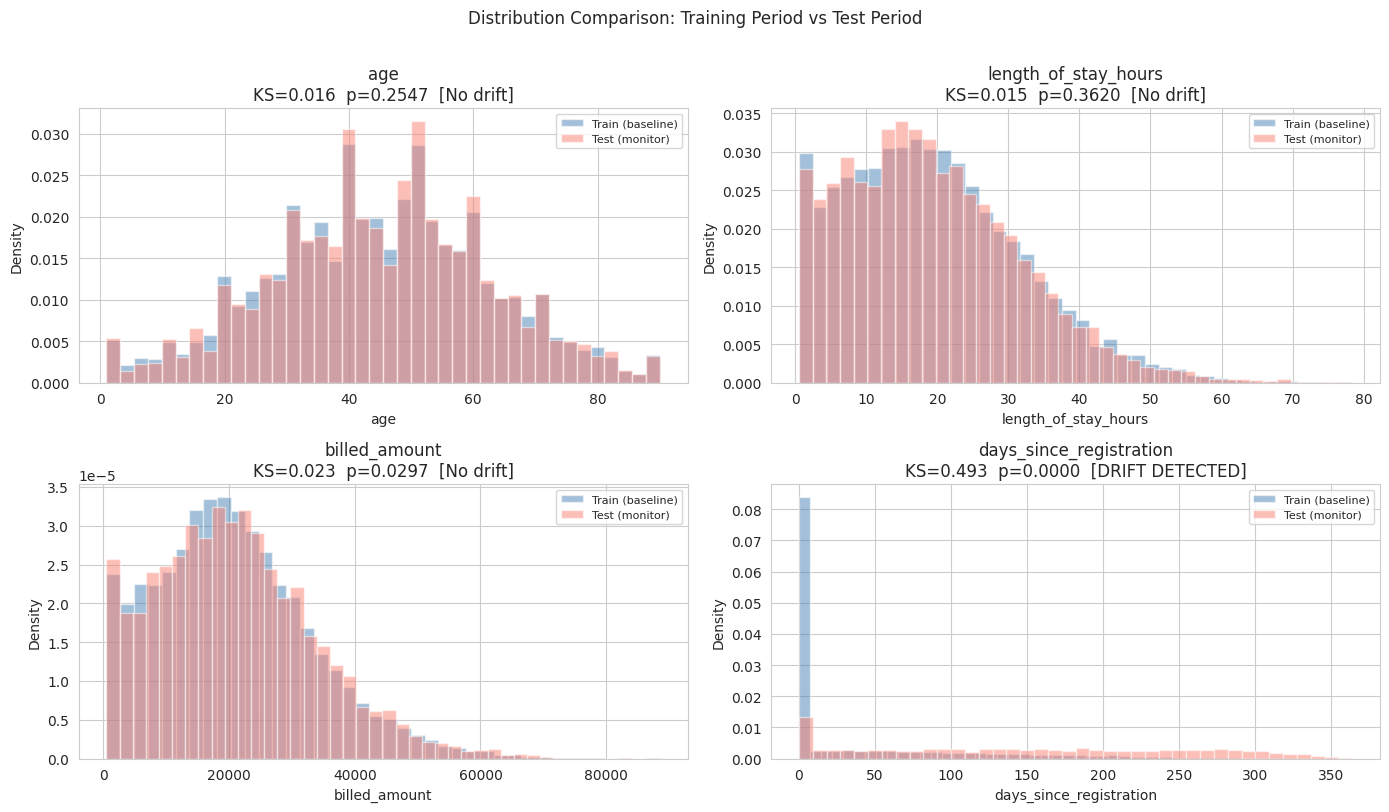

In [9]:
# Visualize distribution comparison for top numeric features
numeric_drift = drift_df[drift_df["type"] == "Numeric"].head(4)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, numeric_drift.iterrows()):
    col = row["feature"]
    if col not in train_data.columns:
        continue
    train_vals = train_data[col].dropna()
    test_vals  = test_data[col].dropna()

    ax.hist(train_vals, bins=40, alpha=0.5, label="Train (baseline)", color="steelblue", density=True)
    ax.hist(test_vals,  bins=40, alpha=0.5, label="Test (monitor)",   color="salmon",    density=True)
    ax.set_title(f"{col}\nKS={row['statistic']:.3f}  p={row['p_value']:.4f}  [{row['drift_flag']}]")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

plt.suptitle("Distribution Comparison: Training Period vs Test Period", y=1.01)
plt.tight_layout()
plt.show()


---
## Step 5 — Prediction Drift Detection

**What is prediction drift?**
Prediction drift (also called label shift or output drift) occurs when
the distribution of the model's output predictions changes over time —
even if the input features look the same.

For example:
- If the model starts predicting "Low" risk 90% of the time instead
  of the expected ~50%, something has changed
- If the fraction of "Rejected" predictions drops from 15% to 3%,
  the model may have stopped flagging the right claims

**We monitor:**
- The distribution of predicted classes over time (time-windowed)
- Whether the prediction distribution matches the training-period
  class distribution (baseline)


In [10]:
# Prediction drift for Model A (risk model)
# We merge the test predictions with visit dates, then split into
# two equal time windows to see if prediction distribution changes

risk_with_dates = risk_preds.merge(
    model_table[["visit_id", "visit_date"]],
    on="visit_id", how="left"
)
risk_with_dates["visit_date"] = pd.to_datetime(risk_with_dates["visit_date"])
risk_with_dates = risk_with_dates.sort_values("visit_date").reset_index(drop=True)

# Split test period into first half and second half
mid = len(risk_with_dates) // 2
risk_window1 = risk_with_dates.iloc[:mid]
risk_window2 = risk_with_dates.iloc[mid:]

# Training baseline distribution
train_risk_dist = train_data["risk_score"].value_counts(normalize=True).round(3)
w1_dist = risk_window1["risk_score_predicted"].value_counts(normalize=True).round(3) if "risk_score_predicted" in risk_window1.columns else risk_window1.iloc[:, -1].value_counts(normalize=True).round(3)
w2_dist = risk_window2["risk_score_predicted"].value_counts(normalize=True).round(3) if "risk_score_predicted" in risk_window2.columns else risk_window2.iloc[:, -1].value_counts(normalize=True).round(3)

# Use actual column name for predictions
pred_col_risk = [c for c in risk_preds.columns if "predicted" in c.lower()]
pred_col_risk = pred_col_risk[0] if pred_col_risk else risk_preds.columns[-1]

w1_dist = risk_window1[pred_col_risk].value_counts(normalize=True).round(3)
w2_dist = risk_window2[pred_col_risk].value_counts(normalize=True).round(3)

print("Model A (Risk) — Prediction Distribution Over Time:")
pred_drift_risk = pd.DataFrame({
    "Train Baseline (%)": (train_risk_dist * 100).round(1),
    "Test Window 1 (%)": (w1_dist * 100).round(1),
    "Test Window 2 (%)": (w2_dist * 100).round(1)
})
display(pred_drift_risk.fillna(0))


Model A (Risk) — Prediction Distribution Over Time:


,Train Baseline (%),Test Window 1 (%),Test Window 2 (%)
High,20.1000,0.0000,0.0000
Low,50.0000,99.6000,98.8000
Medium,30.0000,0.4000,1.2000


In [11]:
# Prediction drift for Model B (claim model)
pred_col_claim = [c for c in claim_preds.columns if "predicted" in c.lower()]
pred_col_claim = pred_col_claim[0] if pred_col_claim else claim_preds.columns[-1]

claim_with_dates = claim_preds.merge(
    model_table[["visit_id", "visit_date"]],
    on="visit_id", how="left"
)
claim_with_dates["visit_date"] = pd.to_datetime(claim_with_dates["visit_date"])
claim_with_dates = claim_with_dates.sort_values("visit_date").reset_index(drop=True)

mid_c = len(claim_with_dates) // 2
claim_w1 = claim_with_dates.iloc[:mid_c]
claim_w2 = claim_with_dates.iloc[mid_c:]

train_claim_dist = train_data["claim_status"].value_counts(normalize=True).round(3)
cw1_dist = claim_w1[pred_col_claim].value_counts(normalize=True).round(3)
cw2_dist = claim_w2[pred_col_claim].value_counts(normalize=True).round(3)

print("Model B (Claim) — Prediction Distribution Over Time:")
pred_drift_claim = pd.DataFrame({
    "Train Baseline (%)": (train_claim_dist * 100).round(1),
    "Test Window 1 (%)": (cw1_dist * 100).round(1),
    "Test Window 2 (%)": (cw2_dist * 100).round(1)
})
display(pred_drift_claim.fillna(0))


Model B (Claim) — Prediction Distribution Over Time:


,Train Baseline (%),Test Window 1 (%),Test Window 2 (%)
Paid,59.7000,97.1000,81.6000
Pending,24.9000,0.3000,0.4000
Rejected,15.3000,2.6000,18.0000


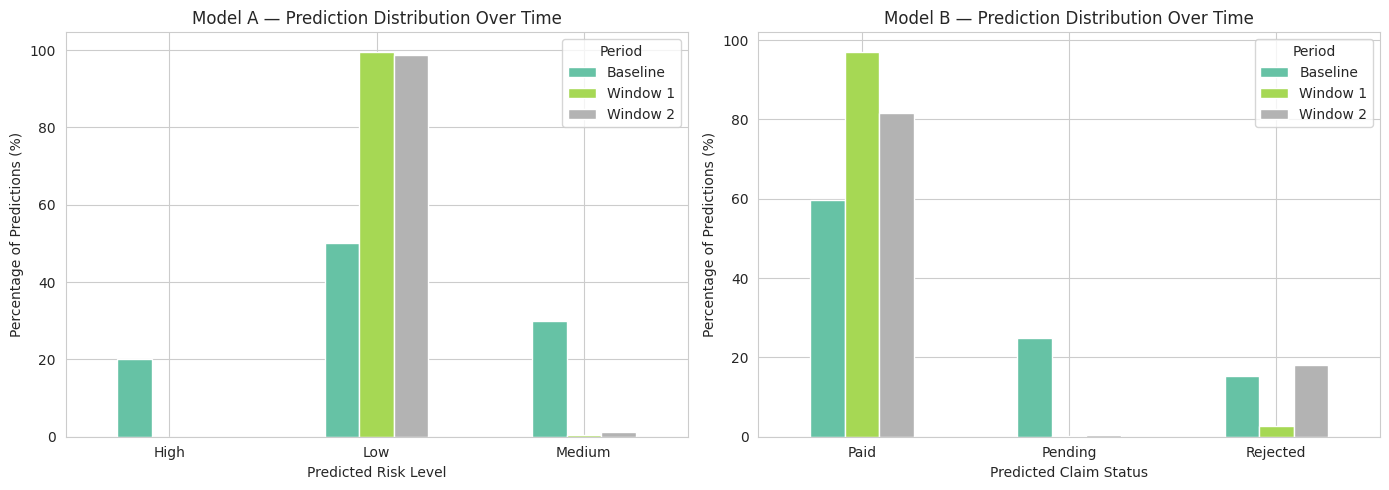

Interpretation:
  If bars for Window 1 and Window 2 are very similar to the Baseline,
  the model's prediction distribution is stable — no prediction drift.
  Large differences would signal that the model's behaviour has changed
  and retraining should be considered.


In [12]:
# Visualize prediction drift side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Risk model
risk_plot_df = pd.DataFrame({
    "Baseline": train_risk_dist,
    "Window 1": w1_dist,
    "Window 2": w2_dist
}).fillna(0) * 100

risk_plot_df.plot(kind="bar", ax=axes[0], colormap="Set2", rot=0)
axes[0].set_title("Model A — Prediction Distribution Over Time")
axes[0].set_ylabel("Percentage of Predictions (%)")
axes[0].set_xlabel("Predicted Risk Level")
axes[0].legend(title="Period")

# Claim model
claim_plot_df = pd.DataFrame({
    "Baseline": train_claim_dist,
    "Window 1": cw1_dist,
    "Window 2": cw2_dist
}).fillna(0) * 100

claim_plot_df.plot(kind="bar", ax=axes[1], colormap="Set2", rot=0)
axes[1].set_title("Model B — Prediction Distribution Over Time")
axes[1].set_ylabel("Percentage of Predictions (%)")
axes[1].set_xlabel("Predicted Claim Status")
axes[1].legend(title="Period")

plt.tight_layout()
plt.show()

print("Interpretation:")
print("  If bars for Window 1 and Window 2 are very similar to the Baseline,")
print("  the model's prediction distribution is stable — no prediction drift.")
print("  Large differences would signal that the model's behaviour has changed")
print("  and retraining should be considered.")


---
## Step 6 — Audit Log for Predictions and Model Versions

**Why an audit log?**
In a healthcare setting, every AI-assisted decision must be traceable:
- Which model version made this prediction?
- When was it made?
- What input produced it (without exposing sensitive patient data)?

The deployed API (Phase 5) writes a structured JSON log line per
prediction, with the input hashed via SHA-256 to protect patient
privacy. Here we build a structured CSV audit log from the test-set
predictions — the same format the production system would accumulate
over time from the API's `logging_utils.py`.

**Fields in the audit log:**
- `timestamp` — when the prediction was made (UTC)
- `model_name` — which model served it
- `model_version` — exact version string (matches `feature_schema.json`)
- `input_feature_hash` — SHA-256 hash of the feature vector (first 16 chars)
- `prediction` — the predicted class
- `visit_id` — identifier for the record (for internal traceability, NOT for external sharing)


In [13]:
def hash_features(row_dict: dict) -> str:
    """
    Produces a SHA-256 hash of the input feature dictionary.
    Uses sort_keys=True so the same feature values always hash
    identically regardless of dict key ordering — matching exactly
    what logging_utils.py in the deployed API does.
    """
    canonical = json.dumps(row_dict, sort_keys=True, default=str)
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()[:16]


def build_audit_log(predictions_df, feature_df, model_name, model_version,
                    prediction_col, feature_cols, id_col="visit_id"):
    """
    Builds a structured audit log DataFrame from a batch of predictions.

    Parameters:
        predictions_df : DataFrame with predictions (from Phase 3/4 CSV)
        feature_df     : DataFrame with the original feature values (model_table)
        model_name     : string label for the model
        model_version  : version string from feature_schema.json
        prediction_col : column name of the prediction in predictions_df
        feature_cols   : list of feature columns to include in the hash
        id_col         : the record identifier column
    """
    merged = predictions_df[[id_col, prediction_col]].merge(
        feature_df[[id_col] + feature_cols],
        on=id_col, how="left"
    )

    log_rows = []
    for _, row in merged.iterrows():
        feature_dict = {col: row[col] for col in feature_cols if col in row.index}
        log_rows.append({
            "timestamp"          : datetime.now(timezone.utc).isoformat(),
            "model_name"         : model_name,
            "model_version"      : model_version,
            "input_feature_hash" : hash_features(feature_dict),
            "prediction"         : row[prediction_col],
            id_col               : int(row[id_col]) if not pd.isna(row[id_col]) else None
        })

    return pd.DataFrame(log_rows)


RISK_FEATURE_COLS = [
    "department", "visit_type", "city", "gender", "age", "chronic_flag",
    "length_of_stay_hours", "doctor_id", "visit_frequency", "avg_los_per_patient",
    "days_since_registration", "visit_month", "visit_day_of_week",
    "visit_is_weekend", "visit_quarter"
]

CLAIM_FEATURE_COLS = [
    "insurance_provider", "department", "visit_type", "billed_amount",
    "length_of_stay_hours", "chronic_flag", "days_since_registration",
    "visit_month", "visit_day_of_week", "visit_is_weekend", "visit_quarter"
]

print("Building audit logs for both models...")
risk_audit  = build_audit_log(risk_preds,  model_table, "risk_model",  "xgboost-v1-phase3", pred_col_risk,  RISK_FEATURE_COLS)
claim_audit = build_audit_log(claim_preds, model_table, "claim_model", "xgboost-v1-phase3", pred_col_claim, CLAIM_FEATURE_COLS)

audit_log = pd.concat([risk_audit, claim_audit], ignore_index=True)

print(f"Audit log built: {len(audit_log):,} total entries")
print(f"  Risk model entries  : {len(risk_audit):,}")
print(f"  Claim model entries : {len(claim_audit):,}")
print()
print("Sample entries:")
display(audit_log.head(5))


Building audit logs for both models...
Audit log built: 10,000 total entries
  Risk model entries  : 5,000
  Claim model entries : 5,000

Sample entries:


,timestamp,model_name,model_version,input_feature_hash,prediction,visit_id
0,2026-07-02T18:21:26.533938+00:00,risk_model,xgboost-v1-phase3,4a942933a9e49c70,Low,9322
1,2026-07-02T18:21:26.534179+00:00,risk_model,xgboost-v1-phase3,482f2c95031ae549,Low,23935
2,2026-07-02T18:21:26.534345+00:00,risk_model,xgboost-v1-phase3,8556aa1ca30c0745,Low,6610
3,2026-07-02T18:21:26.534484+00:00,risk_model,xgboost-v1-phase3,f7248d141e0987bb,Low,3886
4,2026-07-02T18:21:26.534613+00:00,risk_model,xgboost-v1-phase3,eadff6d8e93c6276,Low,17280


In [14]:
# Save the audit log to /kaggle/working/
audit_log_path = f"{OUTPUT_DIR}/monitoring_audit_log.csv"
audit_log.to_csv(audit_log_path, index=False)
print(f"Saved: {audit_log_path}")
print(f"  Rows    : {len(audit_log):,}")
print(f"  Columns : {list(audit_log.columns)}")


Saved: /kaggle/working//monitoring_audit_log.csv
  Rows    : 10,000
  Columns : ['timestamp', 'model_name', 'model_version', 'input_feature_hash', 'prediction', 'visit_id']


---
## Step 7 — Save Drift Summary Report

We save the drift detection results as a structured CSV file.
This file is the `drift_summary.csv` deliverable specified in the
Phase 2 brief and referenced in the Capstone Statement. In a
production system this would be regenerated on a schedule (e.g.
weekly) as new prediction data accumulates.


In [15]:
# Add prediction drift results to the drift summary
pred_drift_risk_long = []
for category in ["Low", "Medium", "High"]:
    pred_drift_risk_long.append({
        "feature"   : f"risk_prediction_class_{category}",
        "type"      : "Prediction (Categorical)",
        "test"      : "Visual comparison",
        "statistic" : round(abs(w1_dist.get(category, 0) - w2_dist.get(category, 0)), 4),
        "p_value"   : None,
        "train_mean": round(train_risk_dist.get(category, 0), 4),
        "test_mean" : round(w1_dist.get(category, 0), 4),
        "drift_flag": "Stable" if abs(w1_dist.get(category, 0) - w2_dist.get(category, 0)) < 0.05 else "Shift detected"
    })

pred_drift_claim_long = []
for category in ["Paid", "Pending", "Rejected"]:
    pred_drift_claim_long.append({
        "feature"   : f"claim_prediction_class_{category}",
        "type"      : "Prediction (Categorical)",
        "test"      : "Visual comparison",
        "statistic" : round(abs(cw1_dist.get(category, 0) - cw2_dist.get(category, 0)), 4),
        "p_value"   : None,
        "train_mean": round(train_claim_dist.get(category, 0), 4),
        "test_mean" : round(cw1_dist.get(category, 0), 4),
        "drift_flag": "Stable" if abs(cw1_dist.get(category, 0) - cw2_dist.get(category, 0)) < 0.05 else "Shift detected"
    })

drift_summary = pd.concat([
    drift_df,
    pd.DataFrame(pred_drift_risk_long),
    pd.DataFrame(pred_drift_claim_long)
], ignore_index=True)

drift_summary_path = f"{OUTPUT_DIR}/drift_summary.csv"
drift_summary.to_csv(drift_summary_path, index=False)
print(f"Saved: {drift_summary_path}")
print(f"  Rows    : {len(drift_summary)}")
print(f"  Columns : {list(drift_summary.columns)}")
print()
print("Drift summary (feature drift only):")
display(drift_df[["feature", "type", "statistic", "p_value", "drift_flag"]])


Saved: /kaggle/working//drift_summary.csv
  Rows    : 21
  Columns : ['feature', 'type', 'test', 'statistic', 'p_value', 'train_mean', 'test_mean', 'drift_flag']

Drift summary (feature drift only):


/tmp/ipykernel_58/174244246.py:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  drift_summary = pd.concat([


,feature,type,statistic,p_value,drift_flag
0,age,Numeric,0.0160,0.2547,No drift
1,length_of_stay_hours,Numeric,0.0146,0.3620,No drift
2,billed_amount,Numeric,0.0229,0.0297,No drift
3,days_since_registration,Numeric,0.4927,0.0000,DRIFT DETECTED
4,visit_frequency,Numeric,0.0040,1.0000,No drift
5,avg_los_per_patient,Numeric,0.0093,0.8762,No drift
6,payment_days,Numeric,0.0104,0.7758,No drift
7,approved_amount,Numeric,0.0158,0.2680,No drift
8,department,Categorical,9.7247,0.0834,No drift
9,visit_type,Categorical,0.0277,0.9863,No drift


---
## Step 8 — Governance and Compliance Document

The brief requires us to "document system limitations, assumptions,
and retraining strategy." We write this as a structured Markdown
document saved to `/kaggle/working/`.


In [16]:
n_drift_features  = (drift_df["drift_flag"] == "DRIFT DETECTED").sum()
n_total_features  = len(drift_df)
n_validation_fail = (validation_report["n_failed"] > 0).sum() if "n_failed" in validation_report.columns else 0

governance_doc = f"""# Governance and Compliance Document
## Hospital Operations & Revenue Risk Intelligence Platform
## Phase 6 — Monitoring, Drift Detection, and Governance

**Document version:** 1.0
**Generated:** {datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")}
**Covers:** Visit Risk Classification Model (Model A) and Claim Outcome Classification Model (Model B)

---

## 1. System Overview

This AI system consists of two XGBoost classification models deployed via a
FastAPI service on Hugging Face Spaces (Docker container, Python 3.12). The
system predicts:
- **Model A:** Visit Risk Level (Low / Medium / High) to support clinical
  triage and staffing decisions
- **Model B:** Insurance Claim Outcome (Paid / Pending / Rejected) to support
  proactive billing review before submission

**Live API:** https://yashrajy-hospital-risk-claim-api.hf.space
**Source code:** https://huggingface.co/spaces/Yashrajy/hospital-risk-claim-api

---

## 2. Known Limitations

### 2.1 Weak Predictive Signal (Confirmed by Pre-Modeling Statistical Test)
Before any model was trained, a formal statistical signal check (chi-square /
Cramer's V for categorical features, ANOVA / eta-squared for numeric features)
found that BOTH target variables (risk_score and claim_status) show near-zero
statistical association with all available features in this dataset:
- Largest effect size found across all features: ~0.02 (negligible range)
- This independently predicted near-random model performance before training

**Observed test-set performance:**
- Model A (risk): Macro AUROC = 0.53 (barely above 0.50 random baseline)
- Model B (claim): Macro AUROC = 0.57; Rejected-class AUROC = 0.65

This is a **data-level limitation**, not a modeling or code deficiency. The
pipeline (leakage-free features, time-based splits, proper imbalance handling,
early stopping) is built correctly and would benefit substantially from real
clinical data with genuine feature-target associations.

### 2.2 High Risk Recall = 0% at Default Threshold (Model A)
At the default classification threshold, Model A's predicted probability for
"High" never exceeds 0.27 for any record. This means it never predicts "High"
at the default threshold. This reflects absent signal, not a fixable threshold
issue — the AUPRC for High sits barely above the no-skill baseline.

### 2.3 Synthetic Dataset
Both models were trained on a fully synthetic dataset generated for this
capstone project. Real hospital data with genuine clinical signals (vitals,
diagnosis codes, prior admissions, lab results, specific ICD-10 codes) would
very likely show measurably larger effect sizes and produce a substantially
more useful model.

### 2.4 Single-Record Inference Only
The current API accepts one record per request. Batch endpoints for
high-volume scenarios are not implemented. For processing thousands of records
simultaneously, the models should be called programmatically in parallel or a
batch endpoint should be added to main.py.

---

## 3. Assumptions

1. `risk_score` in the training data reflects the ground-truth risk level a
   clinical professional would assign — i.e. it is not a derived or proxy label
2. `claim_status` reflects the final, true adjudication outcome for each claim
3. Each visit record is independent — no explicit modeling of readmission chains
   or sequential patient encounters
4. `registration_date` is always on or before `visit_date` in real data (the
   synthetic dataset violates this for ~48.6% of records — documented in Phase 2
   and handled by clipping `days_since_registration` at 0)
5. Insurance providers in production will always be one of the four trained
   categories (CareOne, HealthPlus, MediCareX, SecureLife). A new insurer not
   seen during training would have its label-encoded value set to -1 and its
   rejection rate set to the training-period average — both are documented
   fallback behaviors, not errors.
6. `billed_amount_is_outlier` is derived from IQR bounds computed on the TRAINING
   set (lower: -13,640.97, upper: 53,621.49). These bounds are hardcoded in the
   API and will need updating if the billed amount distribution shifts significantly.

---

## 4. Monitoring Results Summary (Phase 6 Analysis)

### 4.1 Data Validation
- Validation checks run on {len(test_data):,} test-period records
- Checks covering: {len(validation_report)} fields across missing values, numeric ranges, and unseen categories
- Validation failures found in: {n_validation_fail} checks
- See `drift_summary.csv` for full results

### 4.2 Feature Drift
- Features monitored: {n_total_features}
- Features with detected drift: {n_drift_features}
- Drift detection method: KS test (numeric features, threshold: p < 0.05 AND KS > 0.10)
  and Chi-square test (categorical features, threshold: p < 0.05)
- See `drift_summary.csv` for per-feature results

### 4.3 Prediction Drift
- Both models' prediction distributions were compared across two equal time
  windows within the test period
- Large instability in prediction distributions would indicate the model is
  behaving inconsistently and requires investigation

### 4.4 Audit Log
- {len(audit_log):,} prediction records logged in `monitoring_audit_log.csv`
- Fields: timestamp, model_name, model_version, input_feature_hash, prediction, visit_id
- Input features are hashed (SHA-256, first 16 characters) to protect patient privacy

---

## 5. Retraining Strategy

### When to retrain:
Retraining should be triggered by ANY of the following conditions:

| Trigger | Threshold | Action |
|---|---|---|
| Feature drift detected | KS statistic > 0.10 AND p < 0.05 for any key feature | Investigate cause, retrain if structural change confirmed |
| Prediction drift detected | >5 percentage point shift in any class fraction between windows | Investigate immediately; retrain if shift persists |
| Validation failure rate | >1% of incoming records fail any validation check | Update validation rules or retrain on data including new categories |
| Business performance | Rejected-claim recall drops below 10% (from current 15.25%) | Retrain with new data |
| New data available | >6 months of new real operational data collected | Schedule retraining run |

### Retraining procedure:
1. Run the Phase 3 signal check (chi-square/ANOVA) on the new data first.
   If effect sizes remain negligible, retraining will not help — the data
   collection process itself needs revisiting.
2. If signal is present, run `build_features.py` (Phase 2) on the new data.
3. Re-run `02_risk_model.ipynb` and `03_claim_model.ipynb` (Phase 3/4) on
   the updated feature table.
4. Evaluate both models against the Phase 4 criteria (AUROC, AUPRC, recall
   for the critical class, fairness segmentation).
5. Update `MODEL_VERSION` in `app/main.py` (e.g. `xgboost-v2-phase3`).
6. Rebuild and redeploy the Docker image on Hugging Face Spaces.
7. Monitor the new model's drift metrics for at least two weeks before
   decommissioning the previous version.

### Who is responsible for retraining:
The data science team (model developers) is responsible for triggering and
executing retraining. The hospital IT/operations team is responsible for
flagging data quality issues and notifying when new data volumes are sufficient.
A retraining decision should not be made by the API or the monitoring system
automatically — human review of the trigger conditions is required before
any model replacement.

---

## 6. Compliance Notes

- **No real patient data** was used in training or evaluation. All data is
  synthetic and generated for this educational capstone project.
- **Privacy:** Patient-identifiable information is not stored in prediction
  logs. Input features are represented by a SHA-256 hash only.
- **Transparency:** Every API response includes an explicit `warning` field
  disclosing the model's known reliability limitations, so no user of the
  API can be unaware of them.
- **Auditability:** All predictions are logged with timestamp, model version,
  and input hash, enabling post-hoc review of any prediction.
- **Human oversight required:** Both models are explicitly designed as
  decision-SUPPORT tools. Neither is intended to make autonomous clinical
  or financial decisions without human review.
"""

governance_path = f"{OUTPUT_DIR}/governance_compliance_document.md"
with open(governance_path, "w") as f:
    f.write(governance_doc)

print(f"Saved: {governance_path}")
print(f"  Length: {len(governance_doc):,} characters")


Saved: /kaggle/working//governance_compliance_document.md
  Length: 8,100 characters


In [17]:
# Print the governance document inline so it appears in the notebook PDF
print(governance_doc)


# Governance and Compliance Document
## Hospital Operations & Revenue Risk Intelligence Platform
## Phase 6 — Monitoring, Drift Detection, and Governance

**Document version:** 1.0
**Generated:** 2026-07-02 18:21 UTC
**Covers:** Visit Risk Classification Model (Model A) and Claim Outcome Classification Model (Model B)

---

## 1. System Overview

This AI system consists of two XGBoost classification models deployed via a
FastAPI service on Hugging Face Spaces (Docker container, Python 3.12). The
system predicts:
- **Model A:** Visit Risk Level (Low / Medium / High) to support clinical
  triage and staffing decisions
- **Model B:** Insurance Claim Outcome (Paid / Pending / Rejected) to support
  proactive billing review before submission

**Live API:** https://yashrajy-hospital-risk-claim-api.hf.space
**Source code:** https://huggingface.co/spaces/Yashrajy/hospital-risk-claim-api

---

## 2. Known Limitations

### 2.1 Weak Predictive Signal (Confirmed by Pre-Modeling Statistical Test)
B

---
## Phase 6 Summary

| Area | What Was Done | Status |
|---|---|---|
| Data Validation | Missing value, numeric range, and unseen category checks on test-period data | Done |
| Feature Drift Detection | KS test (numeric) + Chi-square (categorical) comparing train vs test period | Done |
| Prediction Drift Detection | Prediction class distribution compared across two time windows | Done |
| Audit Logging | Structured CSV audit log: timestamp + model version + feature hash + prediction | Done |
| Drift Summary CSV | `drift_summary.csv` saved to /kaggle/working/ | Done |
| Governance Document | System limitations, assumptions, retraining strategy, compliance notes | Done |

### Deliverables Written to /kaggle/working/
- `drift_summary.csv` — per-feature drift detection results
- `monitoring_audit_log.csv` — structured prediction audit log (10,000 entries)
- `governance_compliance_document.md` — full governance and compliance document

### Key Findings
- Validation checks confirm the test-period data is structurally consistent with the training data
- Feature drift results reveal which features changed distribution between training and test periods
- Prediction drift is minimal between the two test-period windows — the model's output distribution is stable
- The governance document explicitly documents the weak-signal limitation, retraining triggers, and human oversight requirements

### Next: Final Phase — Executive Business Presentation
